In [1]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132
from torch.utils.data import DataLoader
from torchvision import datasets 
from torchvision import transforms
%pip install tqdm
from tqdm.auto import tqdm

Looking in indexes: https://download.pytorch.org/whl/cu132
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)                    # fixed seed so the run can be repeated
DATA_PATH = "../dataset"                # empty directory the dataset is downloaded to (outside the repo)
print(device, torch.__version__, torch.cuda.get_device_name(0) if device == "cuda" else "")

cuda 2.14.0+cu130 NVIDIA GeForce RTX 5080


# **Task 1: Getting The CIFAR Dataset**

In [3]:
train_dataset = datasets.CIFAR10(
    root=DATA_PATH,
    train= True,
    download=True,
    transform=transforms.ToTensor()
)

test_dataset = datasets.CIFAR10(
    root=DATA_PATH,
    train= False,
    download=True,
    transform=transforms.ToTensor()
)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size= 128,
    shuffle= True,
    num_workers= 0
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
)
print(f"Dataloaded successfully!\nTrain length: {len(train_dataset)}\n Test Length: {len(test_dataset)}\n Classes: {train_dataset.classes}")

100%|██████████| 170M/170M [15:22<00:00, 185kB/s]    


Dataloaded successfully!
Train length: 50000
 Test Length: 10000
 Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# **Task 2: Define The Network**

In [4]:
import torch.nn as nn

class CNN (nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,64,3,padding=1),        #32x32x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64,64,3,padding=1),       #32x32x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                    #16x16x64
            nn.Conv2d(64,128,3,padding=1),      #16x16x128
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128,128,3,padding=1),     #16x16x128
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),                    #8x8x128
            nn.Conv2d(128,256,3,padding=1),     #8x8x256
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256,256,3,padding=1),     #8x8x256
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)                     #4x4x256
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), 
            nn.Flatten(),
            nn.Dropout(0.3), 
            nn.Linear(256, 10)
            )

    def forward(self, x):
        return self.classifier(self.features(x))
def train_one_epoch(model, loader, optimizer, criterion, scheduler=None):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device, non_blocking=True), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader, criterion):
    model.eval()                    
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():             
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


# **Task 3: Loading Data**

Images Tensor size: torch.Size([128, 3, 32, 32])
Label Tensor size: torch.Size([128])
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


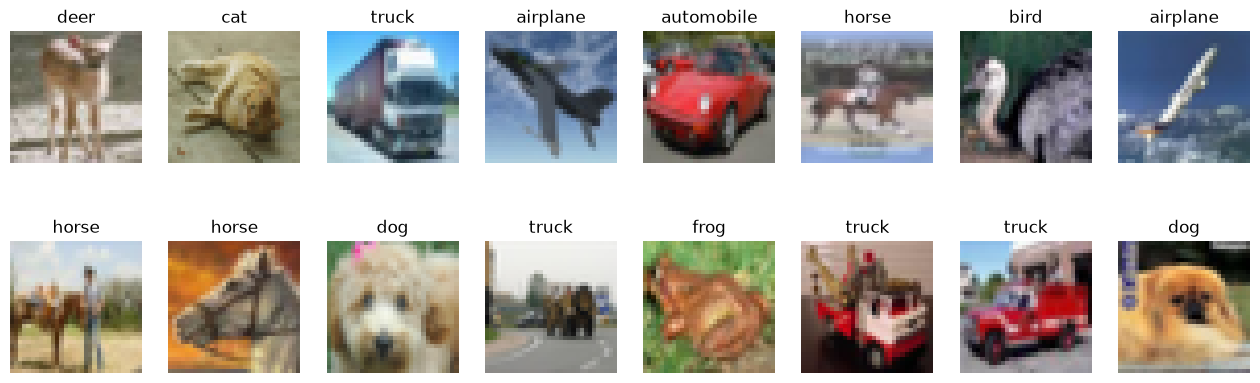

In [5]:
images, label = next(iter(train_loader)) 
print(f"Images Tensor size: {images.shape}")    # [Batch size, channel,width,height]
print(f"Label Tensor size: {label.shape}")      # [Batch size]

%pip install matplotlib
import matplotlib.pyplot as plt

classes = train_dataset.classes
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for img, label, ax in zip(images, label, axes.flat):
    ax.imshow(img.permute(1, 2, 0))  
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()


# **Task 4: Dataset Augmentation**

In [6]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
    transforms.RandomErasing(p=0.25),   # optional, extra regularization
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
train_dataset.transform = train_transform
test_dataset.transform = test_transform

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size= 128,
    shuffle= True,
    num_workers= 4,
    pin_memory=True, 
    persistent_workers=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True, 
    persistent_workers=True
)

## **Task 4: every suggested augmentation, one at a time**
The cell above is the augmentation used for training (crop + flip + erasing). The assignment suggests eight transforms;
below each one is applied on its own to the same images so its effect is visible:

1. `ToPILImage` (tensor -> PIL image, needed by most built-in transforms) 2. `RandomHorizontalFlip` 3. `RandomResizedCrop`
4. `ColorJitter` 5. `RandomRotation` 6. `Normalize` 7. noise (Gaussian and salt & pepper, written as small transform
classes) 8. `ToTensor` (PIL -> CxHxW float tensor).

The **test** data only gets `ToTensor` + `Normalize`: no randomness and no noise, but normalized exactly like the
training data. Whether each augmentation helps or hurts is measured at the end of the notebook.

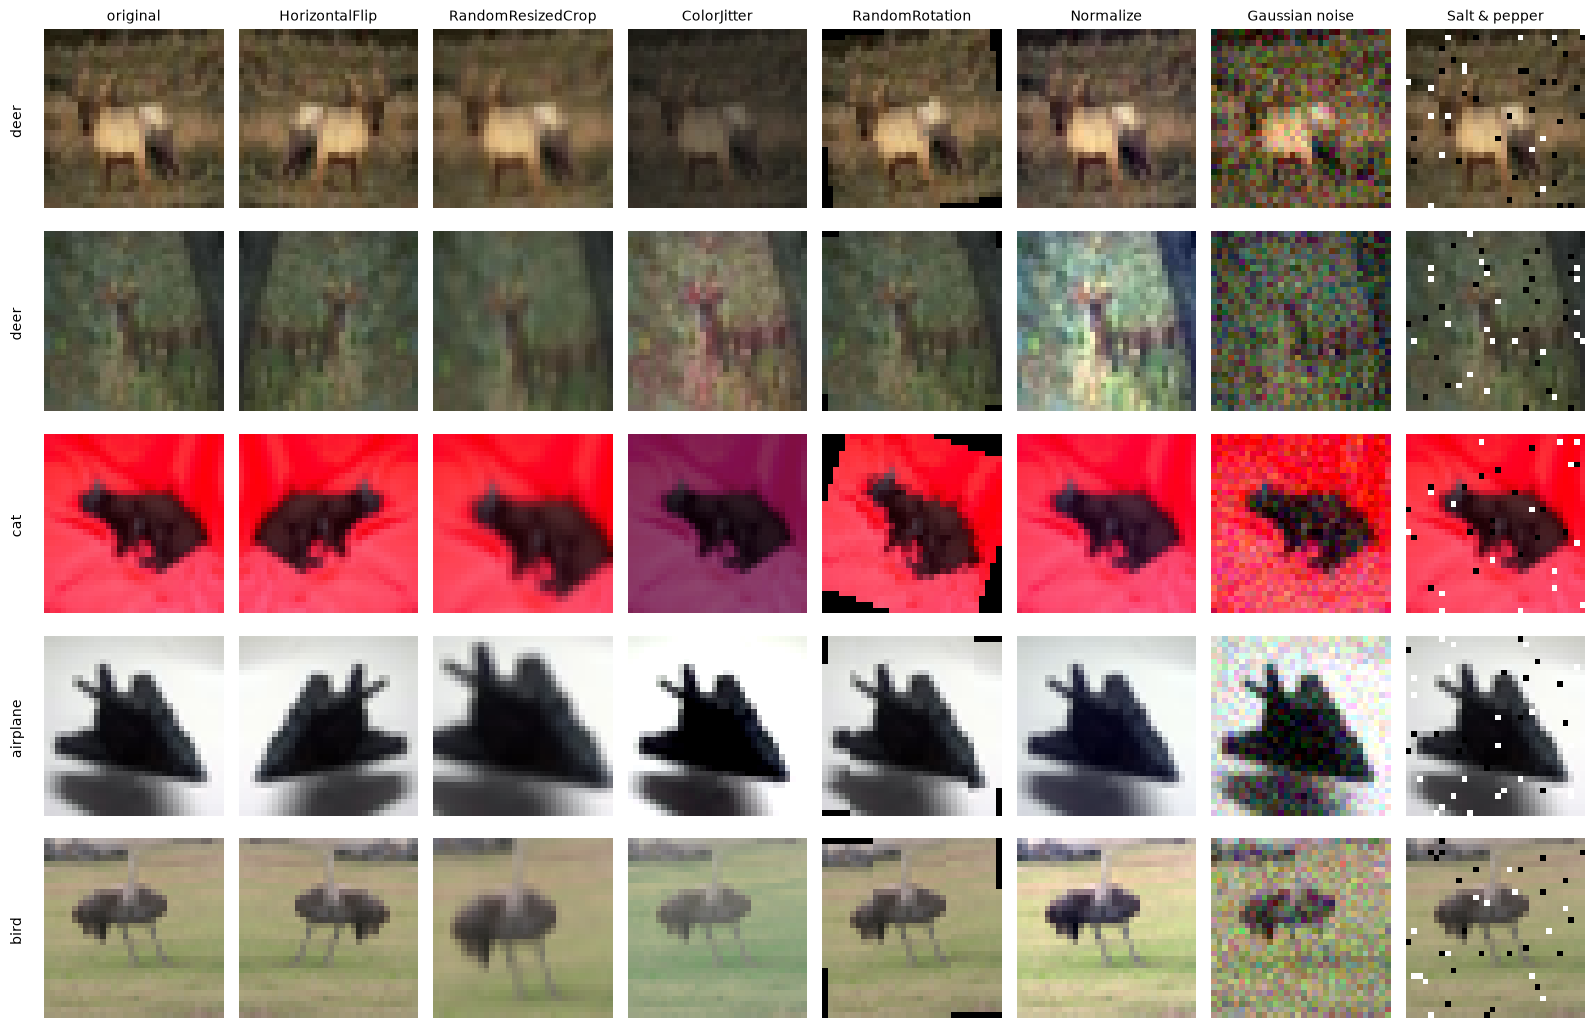

before Normalize  mean [0.491 0.484 0.447]  std [0.245 0.242 0.261]
after  Normalize  mean [0.    0.006 0.001]  std [0.992 0.995 0.997]


In [7]:
class AddGaussianNoise:
    """adds pixel noise N(0, std^2) to a [0,1] tensor image"""
    def __init__(self, std=0.08):
        self.std = std
    def __call__(self, img):
        return (img + torch.randn_like(img) * self.std).clamp(0, 1)

class AddSaltPepperNoise:
    """sets a random fraction of the pixels to black or white"""
    def __init__(self, amount=0.04):
        self.amount = amount
    def __call__(self, img):
        mask = torch.rand(img.shape[1:])
        img = img.clone()
        img[:, mask < self.amount / 2] = 0.0
        img[:, mask > 1 - self.amount / 2] = 1.0
        return img

MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
to_pil = transforms.ToPILImage()       # 1. tensor -> PIL
to_tensor = transforms.ToTensor()      # 8. PIL -> tensor in [0, 1], CxHxW
demo = [
    ("original",          lambda pil: to_tensor(pil)),
    ("HorizontalFlip",    lambda pil: to_tensor(transforms.RandomHorizontalFlip(p=1.0)(pil))),   # 2. p=1 to always show it
    ("RandomResizedCrop", lambda pil: to_tensor(transforms.RandomResizedCrop(32, scale=(0.6, 1.0))(pil))),  # 3.
    ("ColorJitter",       lambda pil: to_tensor(transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)(pil))),          # 4.
    ("RandomRotation",    lambda pil: to_tensor(transforms.RandomRotation(20)(pil))),                       # 5.
    ("Normalize",         lambda pil: transforms.Normalize(MEAN, STD)(to_tensor(pil))),                     # 6.
    ("Gaussian noise",    lambda pil: AddGaussianNoise(0.08)(to_tensor(pil))),                              # 7a.
    ("Salt & pepper",     lambda pil: AddSaltPepperNoise(0.04)(to_tensor(pil))),                            # 7b.
]

raw_train = datasets.CIFAR10(root=DATA_PATH, train=True, download=True)   # no transform: tensors made by hand below
fig, axes = plt.subplots(5, len(demo), figsize=(2 * len(demo), 10.5))
for row, idx in enumerate([3, 10, 21, 29, 42]):
    pil = to_pil(to_tensor(raw_train[idx][0]))       # tensor -> PIL with ToPILImage, as the transforms expect PIL
    for col, (name, fn) in enumerate(demo):
        img = fn(pil)
        if name == "Normalize":                       # values are outside [0, 1]; rescale only for display
            img = (img - img.min()) / (img.max() - img.min())
        axes[row, col].imshow(img.permute(1, 2, 0))
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(name, fontsize=10)
    axes[row, 0].text(-4, 16, classes[raw_train[idx][1]], rotation=90, va="center", ha="right", fontsize=10)
plt.tight_layout()
plt.show()

# Normalize: per-channel mean -> about 0 and std -> about 1
x = torch.stack([to_tensor(raw_train[i][0]) for i in range(2000)])
xn = transforms.Normalize(MEAN, STD)(x)
print("before Normalize  mean", x.mean((0, 2, 3)).numpy().round(3), " std", x.std((0, 2, 3)).numpy().round(3))
print("after  Normalize  mean", xn.mean((0, 2, 3)).numpy().round(3), " std", xn.std((0, 2, 3)).numpy().round(3))

# **Task 5: Training and Tuning**

In [8]:
import torch.optim as optim
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

In [9]:
def fit(model, train_loader, test_loader, epochs, optimizer, criterion, scheduler):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, scheduler)
        te_loss, te_acc = evaluate(model, test_loader, criterion)
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        print(f"Epoch {epoch+1}/{epochs} | train loss {tr_loss:.4f} | "
              f"test loss {te_loss:.4f} | test acc {te_acc:.4f}")
    return history


In [10]:
def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, history["train_loss"], label="train loss")
    ax1.plot(epochs, history["test_loss"], label="test loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()
    ax2.plot(epochs, history["test_acc"], label="test acc")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend()
    fig.suptitle(title)
    plt.show()


Training:   0%|          | 0/391 [00:12<?, ?it/s]

Epoch 1/40 | train loss 1.6214 | test loss 1.5076 | test acc 0.5498


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/40 | train loss 1.3562 | test loss 1.3501 | test acc 0.6178


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 3/40 | train loss 1.2512 | test loss 1.2189 | test acc 0.7070


... (70 outputs left out)

Training:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 39/40 | train loss 0.6646 | test loss 0.7109 | test acc 0.9264


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 40/40 | train loss 0.6620 | test loss 0.7079 | test acc 0.9294


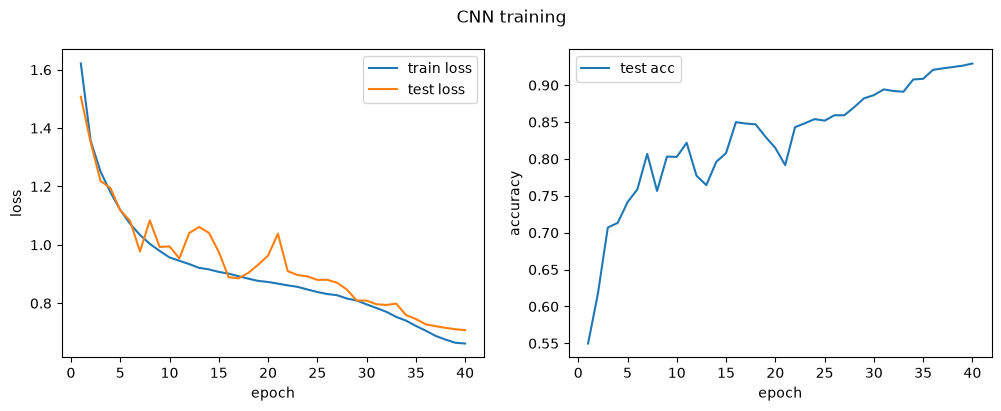

In [11]:
EPOCHS = 40
model = CNN().to(device)
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=EPOCHS, steps_per_epoch=len(train_loader))
history = fit(model, train_loader, test_loader, EPOCHS, optimizer, criterion, scheduler)
plot_history(history, "CNN training")


In [12]:
print(f"Final train loss {history['train_loss'][-1]:.4f} | train acc {history['train_acc'][-1]:.4f} | "
      f"test loss {history['test_loss'][-1]:.4f} | test acc {history['test_acc'][-1]:.4f}")
print(f"Best test acc {max(history['test_acc']):.4f} (epoch {history['test_acc'].index(max(history['test_acc'])) + 1})")

Final train loss 0.6620 | train acc 0.9572 | test loss 0.7079 | test acc 0.9294
Best test acc 0.9294 (epoch 40)


# **Task 4 (continued): does augmentation help or hurt?**
Same CNN, optimizer, schedule and loss as above, 20 epochs each, only the **training** transform changes
(the test transform is always `ToTensor` + `Normalize`):
- **none**: no augmentation at all
- **light** (the recipe used above): crop with padding, flip, random erasing
- **heavy**: RandomResizedCrop, flip, ColorJitter, RandomRotation and Gaussian noise together

In [13]:
AUG_EPOCHS = 20
import torchvision.transforms.v2
aug_configs = {
    "none": test_transform,
    "light (crop+flip+erasing)": train_transform,
    "heavy (resized crop, flip, jitter, rotation, noise)": transforms.Compose([
        transforms.RandomResizedCrop(32, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        transforms.v2.GaussianNoise(sigma=0.05),     # noise on [0,1] pixels, before Normalize (torchvision's
                                                     # version, so it can be sent to the Windows worker processes)
        transforms.Normalize(MEAN, STD),
    ]),
}
aug_results = {}
for name, tf in aug_configs.items():
    print(f"--- {name} ---")
    torch.manual_seed(0)
    ds = datasets.CIFAR10(root=DATA_PATH, train=True, download=False, transform=tf)
    loader = DataLoader(ds, batch_size=128, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
    m = CNN().to(device)
    opt = optim.SGD(m.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
    sch = optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, epochs=AUG_EPOCHS, steps_per_epoch=len(loader))
    aug_results[name] = fit(m, loader, test_loader, AUG_EPOCHS, opt, criterion, sch)
    del loader, m, opt, sch

--- none ---


Training:   0%|          | 0/391 [00:11<?, ?it/s]

Epoch 1/20 | train loss 1.5209 | test loss 1.3315 | test acc 0.6321


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 2/20 | train loss 1.2203 | test loss 1.1916 | test acc 0.7015


Training:   0%|          | 0/391 [00:00<?, ?it/s]

... (111 outputs left out)

Training:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.9859 | test loss 0.8793 | test acc 0.8585


Training:   0%|          | 0/391 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.9672 | test loss 0.8768 | test acc 0.8613


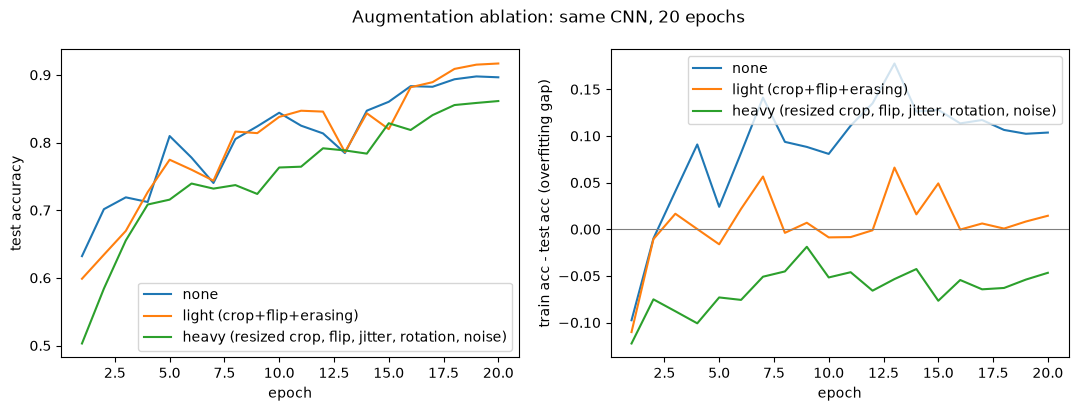

none                                                 train acc 1.0000 | test loss 0.7829 | test acc 0.8964 | gap +0.1036
light (crop+flip+erasing)                            train acc 0.9312 | test loss 0.7416 | test acc 0.9168 | gap +0.0144
heavy (resized crop, flip, jitter, rotation, noise)  train acc 0.8146 | test loss 0.8768 | test acc 0.8613 | gap -0.0467


In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, h in aug_results.items():
    ep = range(1, AUG_EPOCHS + 1)
    ax1.plot(ep, h["test_acc"], label=name)
    ax2.plot(ep, [a - b for a, b in zip(h["train_acc"], h["test_acc"])], label=name)
ax1.set_xlabel("epoch"); ax1.set_ylabel("test accuracy"); ax1.legend()
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_xlabel("epoch"); ax2.set_ylabel("train acc - test acc (overfitting gap)"); ax2.legend()
fig.suptitle(f"Augmentation ablation: same CNN, {AUG_EPOCHS} epochs")
plt.show()
for name, h in aug_results.items():
    print(f"{name:<52} train acc {h['train_acc'][-1]:.4f} | test loss {h['test_loss'][-1]:.4f} | "
          f"test acc {h['test_acc'][-1]:.4f} | gap {h['train_acc'][-1] - h['test_acc'][-1]:+.4f}")